# Seoul Commercial District Sales Patterns: Project 2
**Hyunsoo Lee and Taejoon Ha · CDS 303**

## 1. Research question and audience
What are the main dimensions of variation in the age-group and time-of-day sales shares of Seoul commercial districts in 2025, and how can these differences be compared alongside store composition when screening candidate locations?

Our audience is prospective business owners in Seoul and small-business startup counselors who help them compare locations. They need to understand which age bands account for sales, when sales occur, and what stores are already reported. Our results can guide comparisons, operating-hour hypotheses, and field visits. They do not estimate startup profitability.

We keep the Session 1 design: one district in 2025, six age shares and six time shares as PCA inputs. Store data provide context rather than changing the PCA into a measure of commercial size. Clustering and classification are reserved for later stages.

We reviewed the course's `CDS303_Demo_06.ipynb` (provided under Project_1). We follow its StandardScaler → PCA → explained variance → component coefficients → scores → biplot workflow and random_state=2000. Data audits, integration, component selection and file exports are project-specific additions. Our biplot follows the demo's display scaling; it is not a correlation circle.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import platform
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Works from the repository root or the notebook directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/raw/sales_2025.zip').is_file())
DATA = ROOT / 'data'
RESULTS = ROOT / 'docs/session-2/results'
FIGURES = ROOT / 'docs/session-2/figures'
for folder in [RESULTS, FIGURES, DATA / 'processed']:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', font_scale=0.95)
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__}
display(pd.Series(versions, name='Version'))

python          3.13.9
numpy            2.3.5
pandas           2.3.3
scikit-learn     1.7.2
matplotlib      3.10.6
seaborn         0.13.2
Name: Version, dtype: object

## 2. Load and audit the source files
Both official ZIPs are included, so this notebook needs no network access. Each contains one CP949 CSV. Sales use Korean headers; stores use lowercase English headers. We explicitly rename the store headers using the provider's field descriptions. In particular, `similr_induty_stor_co` is **total stores**, `stor_co` is **general stores**, and `frc_stor_co` is **franchise stores**. Total = general + franchise is checked on every row.

Sources: [estimated sales](https://data.seoul.go.kr/dataList/OA-15572/S/1/datasetView.do), [stores download](https://data.seoul.go.kr/dataList/OA-15577/F/1/datasetView.do), [store field definitions](https://data.seoul.go.kr/dataList/datasetView.do?currentPageNo=1&infId=OA-15577&serviceKind=1&srvType=A). Provider: Seoul Credit Guarantee Foundation. Both datasets refer to commercial districts, not administrative districts or surrounding catchment areas. The provider's spatial-unit notice is shared by the two sources. We check code/name/type agreement for the actual 2025 files; we do not use the older boundary file or claim to validate polygons.

In [2]:
Q, D, I = '기준_년분기_코드', '상권_코드', '서비스_업종_코드'
KEY = [Q, D, I]
TOTAL = '당월_매출_금액'
store_map = {
    'stdr_yyqu_cd': Q, 'trdar_cd': D, 'svc_induty_cd': I,
    'trdar_cd_nm': '상권_코드_명', 'trdar_se_cd': '상권_구분_코드',
    'trdar_se_cd_nm': '상권_구분_코드_명', 'svc_induty_cd_nm': '서비스_업종_코드_명',
    'similr_induty_stor_co': 'total_stores', 'stor_co': 'general_stores',
    'frc_stor_co': 'franchise_stores'}
sales = pd.read_csv(DATA / 'raw/sales_2025.zip', encoding='cp949', dtype={k: str for k in KEY})
stores = pd.read_csv(DATA / 'raw/stores_2025.zip', encoding='cp949',
                     dtype={k: str for k in ['stdr_yyqu_cd', 'trdar_cd', 'svc_induty_cd']})
original_store_columns = stores.columns.tolist()
stores = stores.rename(columns=store_map)
quarters = {'20251', '20252', '20253', '20254'}
audit_rows = []
for name, frame in [('Sales', sales), ('Stores', stores)]:
    for key in KEY:
        frame[key] = frame[key].str.strip()
    assert not frame[KEY].isna().any().any()
    assert not frame[KEY].eq('').any().any()
    assert not frame.duplicated(KEY).any()
    assert set(frame[Q]) == quarters
    audit_rows.append({'Source': name, 'Rows': len(frame), 'Columns': frame.shape[1],
                       'Districts': frame[D].nunique(), 'Industries': frame[I].nunique(),
                       'Missing cells': int(frame.isna().sum().sum()),
                       'Duplicate keys': int(frame.duplicated(KEY).sum())})
source_audit = pd.DataFrame(audit_rows)
display(source_audit)
display(pd.DataFrame({'Sales rows': sales.groupby(Q).size(), 'Store rows': stores.groupby(Q).size()}))

# Save all original column names and inferred data types, not just a preview.
pd.DataFrame({'column': sales.columns, 'dtype': sales.dtypes.astype(str).values}).to_csv(RESULTS / 'sales_schema.csv', index=False)
pd.DataFrame({'original_column': original_store_columns, 'analysis_column': stores.columns,
              'dtype': stores.dtypes.astype(str).values}).to_csv(RESULTS / 'stores_schema.csv', index=False)
display(sales.head(3))
display(stores.head(3))
assert (stores['total_stores'] == stores['general_stores'] + stores['franchise_stores']).all()
assert (stores[['total_stores', 'general_stores', 'franchise_stores']] >= 0).all().all()

,Source,Rows,Columns,Districts,Industries,Missing cells,Duplicate keys
0,Sales,85732,55,1577,62,0,0
1,Stores,304775,14,1650,100,0,0


,Sales rows,Store rows
기준_년분기_코드,,
20251,21427,76383
20252,21452,76238
20253,21520,76169
20254,21333,75985


,기준_년분기_코드,상권_구분_코드,상권_구분_코드_명,상권_코드,상권_코드_명,서비스_업종_코드,서비스_업종_코드_명,당월_매출_금액,...,남성_매출_건수,여성_매출_건수,연령대_10_매출_건수,연령대_20_매출_건수,연령대_30_매출_건수,연령대_40_매출_건수,연령대_50_매출_건수,연령대_60_이상_매출_건수
0,20251,U,관광특구,3001491,이태원 관광특구,CS300015,가방,1569075360,...,2010,5330,0,539,752,990,1393,3666
1,20251,U,관광특구,3001491,이태원 관광특구,CS200030,피부관리실,27388312,...,149,179,0,74,55,106,71,22
2,20251,U,관광특구,3001491,이태원 관광특구,CS200037,노래방,94383079,...,2169,1064,56,1195,1450,368,84,80


,기준_년분기_코드,상권_구분_코드,상권_구분_코드_명,상권_코드,상권_코드_명,서비스_업종_코드,서비스_업종_코드_명,general_stores,total_stores,opbiz_rt,opbiz_stor_co,clsbiz_rt,clsbiz_stor_co,franchise_stores
0,20251,A,골목상권,3110001,이북5도청사,CS100001,한식음식점,12,13,0,0,8,1,1
1,20251,A,골목상권,3110001,이북5도청사,CS100003,일식음식점,1,1,0,0,0,0,0
2,20251,A,골목상권,3110001,이북5도청사,CS100008,분식전문점,2,2,0,0,0,0,0


In [3]:
age_columns = ['연령대_10_매출_금액', '연령대_20_매출_금액', '연령대_30_매출_금액',
               '연령대_40_매출_금액', '연령대_50_매출_금액', '연령대_60_이상_매출_금액']
windows = ['00~06', '06~11', '11~14', '14~17', '17~21', '21~24']
time_columns = [f'시간대_{w}_매출_금액' for w in windows]
amount_columns = [TOTAL, '당월_매출_건수', '주중_매출_금액', '주말_매출_금액'] + age_columns + time_columns
assert (sales[amount_columns] >= 0).all().all()
sales_checks = pd.Series({
    'Nonpositive total sales rows': int((sales[TOTAL] <= 0).sum()),
    'Zero age-attributed sales rows': int(sales[age_columns].sum(axis=1).eq(0).sum()),
    'Age amounts differ from total': int(sales[age_columns].sum(axis=1).ne(sales[TOTAL]).sum()),
    'Time amounts differ from total': int(sales[time_columns].sum(axis=1).ne(sales[TOTAL]).sum()),
    'Weekday/weekend differ from total': int((sales['주중_매출_금액'] + sales['주말_매출_금액']).ne(sales[TOTAL]).sum())
})
display(sales_checks)
assert sales_checks['Time amounts differ from total'] == 0
assert sales_checks['Weekday/weekend differ from total'] == 0

# No duplicated category labels or aggregate 'all industries' category.
category_map = stores[[I, '서비스_업종_코드_명']].drop_duplicates()
assert category_map[I].is_unique
assert not category_map['서비스_업종_코드_명'].str.contains('전체|합계|총계').any()
category_map.to_csv(RESULTS / 'industry_codes.csv', index=False)
key_audit = sales[KEY].merge(stores[KEY], how='outer', on=KEY,
                            validate='one_to_one', indicator=True)
display(key_audit['_merge'].value_counts(sort=False))

# Verify labels/types on matching raw keys before using district summaries.
labels = ['상권_코드_명', '상권_구분_코드', '상권_구분_코드_명', '서비스_업종_코드_명']
label_check = sales[KEY + labels].merge(stores[KEY + labels], on=KEY, validate='one_to_one', suffixes=('_sales', '_stores'))
label_mismatches = {c: int(label_check[c + '_sales'].ne(label_check[c + '_stores']).sum()) for c in labels}
display(pd.Series(label_mismatches, name='Mismatched labels on shared keys'))
assert sum(label_mismatches.values()) == 0

Nonpositive total sales rows             0
Zero age-attributed sales rows           1
Age amounts differ from total        50298
Time amounts differ from total           0
Weekday/weekend differ from total        0
dtype: int64

_merge
left_only          0
right_only    219043
both           85732
Name: count, dtype: int64

상권_코드_명        0
상권_구분_코드       0
상권_구분_코드_명     0
서비스_업종_코드_명    0
Name: Mismatched labels on shared keys, dtype: int64

## 3. Aggregate first, then integrate
Sales are flows: sum the reported quarterly industry amounts for each district, then calculate shares. Stores are stocks: sum distinct industries within each district-quarter, then average the quarterly totals. We keep **all 100 reported store categories**, including categories absent from the 62-category sales file. We do not discard stores by restricting them to matched sales rows.

The final join is a left one-to-one district-code merge. Unmatched store values stay missing. Observed zeros remain zeros. Missing industry-quarter rows are not replaced by zeros. Four-quarter district coverage does not mean every industry appears in every quarter.

In [4]:
sales_annual = sales.groupby(D)[amount_columns].sum(min_count=1)
sales_annual['sales_quarters'] = sales.groupby(D)[Q].nunique()
sales_annual['sales_categories'] = sales.groupby(D)[I].nunique()
industry_coverage = sales.groupby([D, I])[Q].nunique()
sales_annual['incomplete_industries'] = industry_coverage.lt(4).groupby(level=0).sum()
for col in ['상권_코드_명', '상권_구분_코드', '상권_구분_코드_명']:
    assert sales.groupby(D)[col].nunique().max() == 1
    sales_annual[col] = sales.groupby(D)[col].first()
for col in ['상권_코드_명', '상권_구분_코드', '상권_구분_코드_명']:
    assert stores.groupby(D)[col].nunique().max() == 1
    shared = sales_annual[[col]].join(stores.groupby(D)[col].first(), rsuffix='_stores', how='inner')
    assert shared[col].eq(shared[col + '_stores']).all()

store_counts = ['total_stores', 'general_stores', 'franchise_stores']
store_quarterly = stores.groupby([D, Q])[store_counts].sum(min_count=1)
store_annual = store_quarterly.groupby(D).mean().add_prefix('mean_')
store_annual['store_quarters'] = store_quarterly.groupby(D).size()
store_annual['franchise_share'] = 100 * store_annual['mean_franchise_stores'] / store_annual['mean_total_stores'].where(store_annual['mean_total_stores'] > 0)
store_quarterly.reset_index().to_csv(DATA / 'processed/store_quarterly.csv', index=False)

integrated = sales_annual.reset_index().merge(store_annual.reset_index(), on=D,
                    how='left', validate='one_to_one', indicator='store_match')
assert len(integrated) == len(sales_annual)
assert integrated[D].is_unique
merge_audit = pd.DataFrame({
    'Measure': ['Sales districts before merge', 'Store districts before merge', 'Rows after left merge',
                'Unique districts after merge', 'Matched sales districts', 'Unmatched sales districts',
                'Store-only districts', 'Sales district match rate (%)'],
    'Value': [len(sales_annual), len(store_annual), len(integrated), integrated[D].nunique(),
              integrated['store_match'].eq('both').sum(), integrated['store_match'].eq('left_only').sum(),
              len(set(store_annual.index) - set(sales_annual.index)), 100 * integrated['store_match'].eq('both').mean()]})
display(merge_audit)
display(integrated[['sales_quarters', 'store_quarters']].value_counts().rename('Districts'))
display(integrated[['sales_categories', 'incomplete_industries', 'mean_total_stores', 'franchise_share']].describe())

,Measure,Value
0,Sales districts before merge,"1,577.000"
1,Store districts before merge,"1,650.000"
2,Rows after left merge,"1,577.000"
3,Unique districts after merge,"1,577.000"
4,Matched sales districts,"1,577.000"
5,Unmatched sales districts,0.000
6,Store-only districts,73.000
7,Sales district match rate (%),100.000


sales_quarters  store_quarters
4               4                 1560
2               4                    9
3               4                    5
1               4                    3
Name: Districts, dtype: int64

,sales_categories,incomplete_industries,mean_total_stores,franchise_share
count,"1,577.000","1,577.000","1,577.000","1,577.000"
mean,14.424,1.680,326.856,7.826
std,11.583,1.619,666.558,4.429
min,1.000,0.000,7.750,0.000
25%,5.000,0.000,80.250,4.937
50%,11.000,1.000,160.500,7.459
75%,21.000,3.000,302.500,10.334
max,54.000,9.000,"13,171.000",31.250


## 4. Features and preprocessing
Age shares use the sum of the six age amounts as denominator, since total sales can include purchases without age attribution. Time shares use total sales, which the six time windows reconcile to. The provider explains the age/total difference in its [sales FAQ](https://data.seoul.go.kr/dataList/OA-15572/A/1/datasetView.do).

We select districts with all four sales quarters and finite, positive denominators. Store information is context, so a missing store record would not automatically remove a valid sales profile. We report its missingness instead. We do not impose an arbitrary volume threshold or delete unusual profiles. Context summaries flag low age coverage and small transaction totals for cautious interpretation.

All 12 PCA inputs are numerical percentages; no categorical encoding is used. IDs, category/quarter codes and raw totals are excluded. Weekend, scale and store measures remain context variables to keep the PCA focused on age/time composition.

In [5]:
age_features = ['age_10s', 'age_20s', 'age_30s', 'age_40s', 'age_50s', 'age_60plus']
time_features = ['time_00_06', 'time_06_11', 'time_11_14', 'time_14_17', 'time_17_21', 'time_21_24']
features = age_features + time_features
age_total = integrated[age_columns].sum(axis=1)
for source, feature in zip(age_columns, age_features):
    integrated[feature] = integrated[source] / age_total.where(age_total > 0) * 100
for source, feature in zip(time_columns, time_features):
    integrated[feature] = integrated[source] / integrated[TOTAL].where(integrated[TOTAL] > 0) * 100
integrated['age_coverage'] = 100 * age_total / integrated[TOTAL].where(integrated[TOTAL] > 0)
integrated['weekend_share'] = 100 * integrated['주말_매출_금액'] / (integrated['주중_매출_금액'] + integrated['주말_매출_금액']).replace(0, np.nan)
integrated['sales_per_transaction'] = integrated[TOTAL] / integrated['당월_매출_건수'].replace(0, np.nan)
integrated['exclusion_reason'] = 'Included'
integrated.loc[integrated['sales_quarters'].ne(4), 'exclusion_reason'] = 'Incomplete sales year'
invalid = ~np.isfinite(integrated[features]).all(axis=1)
integrated.loc[integrated['exclusion_reason'].eq('Included') & invalid, 'exclusion_reason'] = 'Invalid sales shares'
analysis = integrated.loc[integrated['exclusion_reason'].eq('Included')].copy().set_index(D)
X = analysis[features]
assert np.isfinite(X).all().all()
assert np.allclose(X[age_features].sum(axis=1), 100)
assert np.allclose(X[time_features].sum(axis=1), 100)
assert X.std().gt(0).all()
exclusions = integrated['exclusion_reason'].value_counts().rename_axis('Status').reset_index(name='Districts')
display(exclusions)
feature_summary = X.describe().T
feature_summary['missing'] = X.isna().sum()
feature_summary['zero_values'] = X.eq(0).sum()
display(feature_summary)
display(analysis[['age_coverage', '당월_매출_건수', 'mean_total_stores', 'franchise_share']].describe())
display(analysis[['mean_total_stores', 'franchise_share']].isna().sum().rename('Missing context'))

variable_rows = []
for source, feature in zip(age_columns + time_columns, features):
    denominator = 'sum of six age amounts' if feature in age_features else TOTAL
    variable_rows.append([feature, f'100 × sum({source}) / {denominator}', '%', 'PCA input',
                          'Age/time composition; positive denominator, then StandardScaler'])
variable_rows += [
    ['age_coverage', '100 × sum(age amounts) / total sales', '%', 'Context', 'Age attribution quality'],
    ['weekend_share', '100 × weekend / (weekday + weekend)', '%', 'Context', 'Trading-day context'],
    [TOTAL, 'sum of reported quarterly industry sales', 'KRW', 'Context', 'Scale; excluded from PCA'],
    ['sales_per_transaction', 'sales / transactions', 'KRW/transaction', 'Context', 'Positive transaction denominator'],
    ['mean_total_stores', 'mean of quarterly sums of similr_induty_stor_co', 'stores', 'Context', 'All 100 store categories; unmatched stays missing'],
    ['franchise_share', '100 × mean franchise stores / mean total stores', '%', 'Context', 'Same quarters/categories; positive denominator'],
    [D + ', 상권_코드_명', 'district code/name', 'identifier', 'Identifier', 'Join/display only'],
    [Q + ', ' + I, 'quarter/category codes', 'identifier', 'Excluded', 'Grouping/linkage only'],
    ['상권_구분_코드', 'official district type', 'categorical', 'Context', 'No encoding or PCA input'],
    ['Other raw amount/count breakdowns', 'original source columns', 'KRW/count', 'Excluded', 'Redundant breakdowns or outside age/time question']]
variables = pd.DataFrame(variable_rows, columns=['Variable', 'Formula / source', 'Unit', 'Role', 'Reason / preparation'])
display(variables)

,Status,Districts
0,Included,1560
1,Incomplete sales year,17


,count,mean,std,min,25%,50%,75%,max,missing,zero_values
age_10s,"1,560.000",0.420,0.711,0.000,0.105,0.235,0.447,11.255,0,63
age_20s,"1,560.000",8.886,8.005,0.000,3.882,6.615,10.744,60.742,0,10
age_30s,"1,560.000",17.985,8.459,0.000,12.063,16.717,22.892,90.047,0,8
age_40s,"1,560.000",22.551,10.194,0.696,16.635,20.358,25.516,81.508,0,0
age_50s,"1,560.000",23.589,6.469,0.684,20.161,23.737,26.861,76.293,0,0
age_60plus,"1,560.000",26.569,13.712,0.000,16.549,25.428,34.849,89.853,0,3
time_00_06,"1,560.000",3.039,3.669,0.000,0.447,1.916,4.226,30.826,0,132
time_06_11,"1,560.000",9.958,6.713,0.000,5.571,9.325,13.050,47.626,0,15
time_11_14,"1,560.000",25.595,9.185,0.000,19.996,24.750,29.533,80.371,0,1
time_14_17,"1,560.000",22.120,8.274,0.280,16.584,21.859,26.943,58.299,0,0


,age_coverage,당월_매출_건수,mean_total_stores,franchise_share
count,"1,560.000","1,560.000","1,560.000","1,560.000"
mean,90.598,"1,956,847.872",328.647,7.855
std,10.078,"4,874,467.934",667.791,4.404
min,11.822,210.000,12.000,0.000
25%,87.443,"149,115.750",82.688,5.010
50%,93.974,"600,723.500",161.750,7.464
75%,97.250,"1,740,142.500",304.812,10.340
max,100.000,"77,147,439.000","13,171.000",31.250


mean_total_stores    0
franchise_share      0
Name: Missing context, dtype: int64

,Variable,Formula / source,Unit,Role,Reason / preparation
0,age_10s,100 × sum(연령대_10_매출_금액) / sum of six age amounts,%,PCA input,"Age/time composition; positive denominator, th..."
1,age_20s,100 × sum(연령대_20_매출_금액) / sum of six age amounts,%,PCA input,"Age/time composition; positive denominator, th..."
2,age_30s,100 × sum(연령대_30_매출_금액) / sum of six age amounts,%,PCA input,"Age/time composition; positive denominator, th..."
3,age_40s,100 × sum(연령대_40_매출_금액) / sum of six age amounts,%,PCA input,"Age/time composition; positive denominator, th..."
4,age_50s,100 × sum(연령대_50_매출_금액) / sum of six age amounts,%,PCA input,"Age/time composition; positive denominator, th..."
5,age_60plus,100 × sum(연령대_60_이상_매출_금액) / sum of six age am...,%,PCA input,"Age/time composition; positive denominator, th..."
6,time_00_06,100 × sum(시간대_00~06_매출_금액) / 당월_매출_금액,%,PCA input,"Age/time composition; positive denominator, th..."
7,time_06_11,100 × sum(시간대_06~11_매출_금액) / 당월_매출_금액,%,PCA input,"Age/time composition; positive denominator, th..."
8,time_11_14,100 × sum(시간대_11~14_매출_금액) / 당월_매출_금액,%,PCA input,"Age/time composition; positive denominator, th..."
9,time_14_17,100 × sum(시간대_14~17_매출_금액) / 당월_매출_금액,%,PCA input,"Age/time composition; positive denominator, th..."


## 5. Standardize and apply PCA
Following Demo 6, StandardScaler centers each input and divides by its population standard deviation. Although all inputs are percentages, their spreads differ, so this gives equal initial variance to each variable. It can also increase the influence of a low-spread age band. Each district has equal weight in PCA, regardless of sales scale.

Each six-share block sums to 100%, creating two linear dependencies. The standardized data therefore have at most 10 nonzero dimensions. We keep all 12 interpretable shares as planned, but do not treat the final near-zero components as useful information. This is a descriptive PCA of compositions, not a log-ratio analysis.

Retained components: 6
Numerical matrix rank: 10


,Component,Eigenvalue,Explained variance (%),Cumulative variance (%)
0,PC1,3.991,33.235,33.235
1,PC2,1.793,14.932,48.167
2,PC3,1.500,12.492,60.659
3,PC4,1.177,9.805,70.463
4,PC5,1.069,8.900,79.363
5,PC6,0.933,7.774,87.137
6,PC7,0.588,4.899,92.036
7,PC8,0.536,4.468,96.504
8,PC9,0.224,1.864,98.368
9,PC10,0.196,1.632,100.000


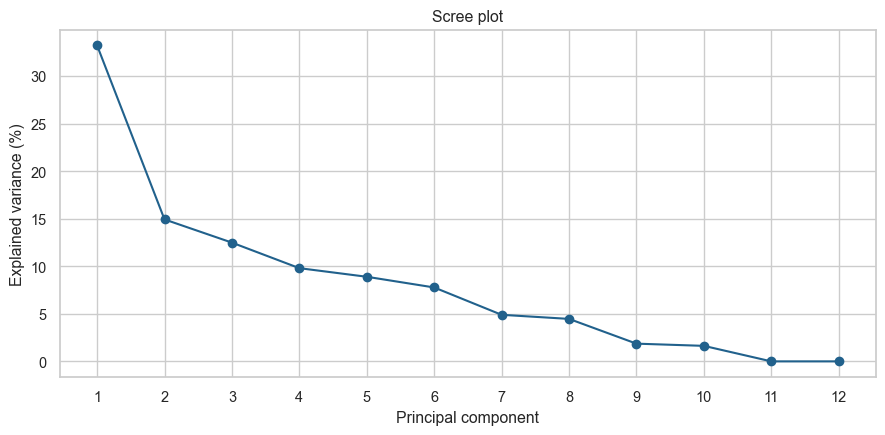

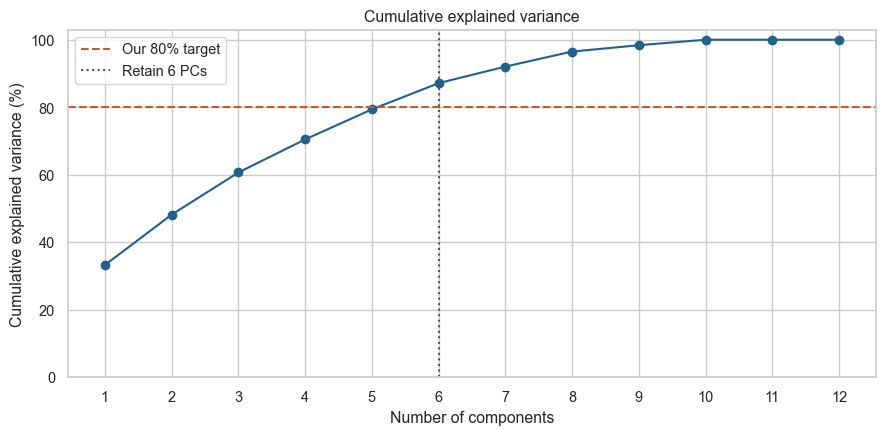

In [6]:
scaler = StandardScaler()
X_st = scaler.fit_transform(X)
pca = PCA(n_components=None, svd_solver='full', random_state=2000)
scores = pca.fit_transform(X_st)
pc_names = [f'PC{i}' for i in range(1, len(features) + 1)]
variance = pd.DataFrame({'Component': pc_names, 'Eigenvalue': pca.explained_variance_,
                         'Explained variance (%)': pca.explained_variance_ratio_ * 100,
                         'Cumulative variance (%)': np.cumsum(pca.explained_variance_ratio_) * 100})
# 80% is our compression target, not an instructor-specified cutoff.
n_keep = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.80) + 1)
display(variance)
print('Retained components:', n_keep)
print('Numerical matrix rank:', np.linalg.matrix_rank(X_st))
assert np.allclose(X_st.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_st.std(axis=0), 1)

x_axis = np.arange(1, len(features) + 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_axis, variance['Explained variance (%)'], marker='o', color='#21618c')
ax.set(xlabel='Principal component', ylabel='Explained variance (%)', title='Scree plot', xticks=x_axis)
fig.tight_layout()
fig.savefig(FIGURES / 'scree.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_axis, variance['Cumulative variance (%)'], marker='o', color='#21618c')
ax.axhline(80, color='#bd5d34', linestyle='--', label='Our 80% target')
ax.axvline(n_keep, color='#555555', linestyle=':', label=f'Retain {n_keep} PCs')
ax.set(xlabel='Number of components', ylabel='Cumulative explained variance (%)',
       title='Cumulative explained variance', xticks=x_axis, ylim=(0, 103))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'cumulative.png', dpi=160)
plt.show()

## 6. Component coefficients and interpretation
As in Demo 6, our loading table contains eigenvector coefficients: `pca.components_.T`. A score is the weighted sum of standardized inputs using these coefficients. These are **not variable–component correlation coefficients**. We rank absolute coefficients within each retained component and read positive and negative ends together. Component signs are arbitrary; their relative directions are what matter.

,PC1,PC2,PC3,PC4,PC5,PC6
age_10s,0.205,0.292,0.009,-0.293,0.645,0.204
age_20s,0.349,0.418,-0.085,-0.175,0.185,0.032
age_30s,0.328,0.324,0.016,0.171,-0.410,-0.036
age_40s,-0.014,-0.131,0.671,0.421,0.117,0.044
age_50s,-0.169,-0.418,-0.006,-0.179,0.146,0.612
age_60plus,-0.327,-0.165,-0.457,-0.217,-0.044,-0.329
time_00_06,0.306,-0.127,-0.366,0.374,0.129,0.034
time_06_11,-0.271,0.094,-0.276,0.485,0.258,0.175
time_11_14,-0.251,0.378,0.053,-0.185,-0.417,0.439
time_14_17,-0.315,0.195,0.213,-0.014,0.288,-0.470


,Component,Variable,Coefficient
0,PC1,time_21_24,0.421
1,PC1,age_20s,0.349
2,PC1,age_30s,0.328
3,PC1,age_60plus,-0.327
4,PC2,age_20s,0.418
5,PC2,age_50s,-0.418
6,PC2,time_17_21,-0.380
7,PC2,time_11_14,0.378
8,PC3,age_40s,0.671
9,PC3,age_60plus,-0.457


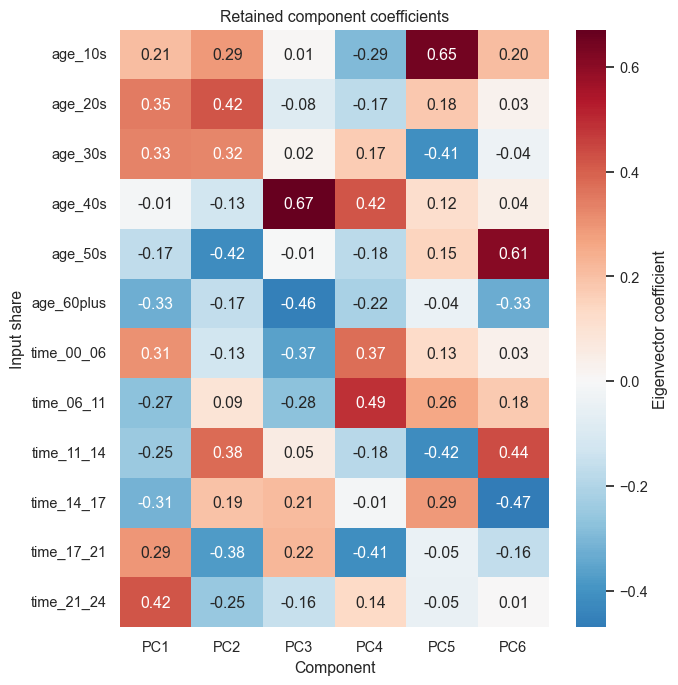

In [7]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=pc_names)
display(loadings.iloc[:, :n_keep])
top_rows = []
for component in pc_names[:n_keep]:
    for feature in loadings[component].abs().nlargest(4).index:
        top_rows.append({'Component': component, 'Variable': feature, 'Coefficient': loadings.loc[feature, component]})
top_loadings = pd.DataFrame(top_rows)
display(top_loadings)
fig, ax = plt.subplots(figsize=(max(6, n_keep * 1.15), 7))
sns.heatmap(loadings.iloc[:, :n_keep], annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
            cbar_kws={'label': 'Eigenvector coefficient'})
ax.set(title='Retained component coefficients', xlabel='Component', ylabel='Input share')
fig.tight_layout()
fig.savefig(FIGURES / 'loadings.png', dpi=160)
plt.show()
score_df = pd.DataFrame(scores, index=X.index, columns=pc_names)

## 7. Biplot and illustrative district comparisons
Following the Demo 6 function, each score coordinate is divided by the observed range on that component. Arrows show the unscaled eigenvector coefficients for PC1 and PC2. We label the score axes accordingly. This display supports approximate score direction and coefficient-sign comparisons; arrow angles are not exact variable correlations and arrow lengths are not percentages of explained variance. Distances here differ from distances in the original retained score space because each displayed axis has its own range scale.

We label four illustrative cases: the lowest and highest scores on PC1 and PC2, with district code breaking ties. They are extremes selected for illustration, not representative samples or confirmed groups. All other districts remain visible. We use short case IDs in the plot and retain Korean district names in the comparison table.

,Case,Selected end,상권_코드_명,age_10s,age_20s,age_30s,age_40s,age_50s,...,age_coverage,당월_매출_건수,sales_categories,incomplete_industries,mean_total_stores,franchise_share,PC1,PC2
상권_코드,,,,,,,,,,,,,,,,,
3130254,C1,PC1 low,남서울상가,0.000,0.000,0.000,7.765,2.382,...,100.000,1130,1,0,19.000,0.000,-4.953,2.198
3130069,C2,PC1 high,"한양대앞상점가(한양시장, 왕십리맛골목)",6.226,50.205,21.586,8.313,10.499,...,91.828,3815873,15,1,234.500,20.576,7.687,3.860
3110898,C3,PC2 low,청림동주민센터(상도중학교),0.000,2.170,5.683,17.280,54.821,...,92.350,1991,1,0,56.750,2.203,3.879,-6.295
3110340,C4,PC2 high,인수중학교,0.011,0.129,90.047,5.860,1.557,...,98.342,5914,4,1,48.000,9.896,0.638,6.945


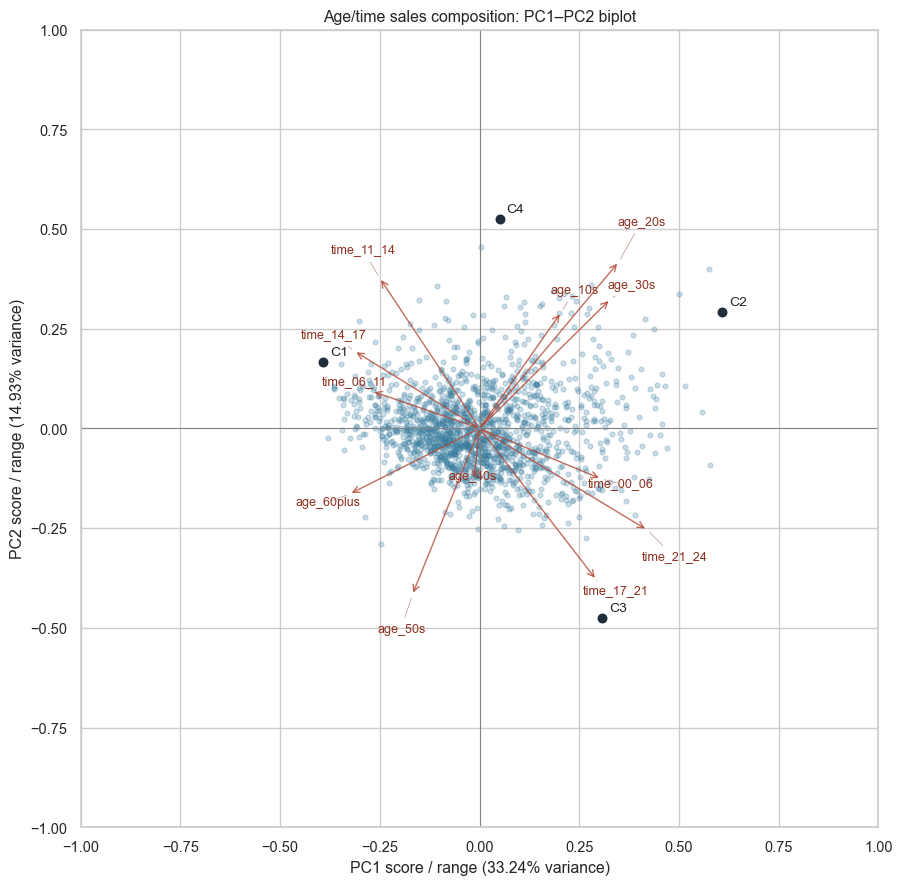

In [8]:
case_ids = []
case_ends = []
for component in ['PC1', 'PC2']:
    ordered = score_df.sort_values(component, kind='stable')
    for end, district in [('low', ordered.index[0]), ('high', ordered.index[-1])]:
        case_ids.append(district)
        case_ends.append(f'{component} {end}')
cases = analysis.loc[case_ids, ['상권_코드_명'] + features + ['age_coverage', '당월_매출_건수', 'sales_categories', 'incomplete_industries', 'mean_total_stores', 'franchise_share']].copy()
cases.insert(0, 'Selected end', case_ends)
cases.insert(0, 'Case', [f'C{i+1}' for i in range(len(cases))])
cases[['PC1', 'PC2']] = score_df.loc[case_ids, ['PC1', 'PC2']].to_numpy()
display(cases)

fig, ax = plt.subplots(figsize=(11, 9))
scaled_scores = scores[:, :2] / np.ptp(scores[:, :2], axis=0)
ax.scatter(scaled_scores[:, 0], scaled_scores[:, 1], s=12, alpha=0.25, color='#377c9e', label='Districts')
for j, feature in enumerate(features):
    u, v = loadings.loc[feature, ['PC1', 'PC2']]
    ax.annotate('', xy=(u, v), xytext=(0, 0), arrowprops={'arrowstyle': '->', 'color': '#b34735', 'alpha': 0.8})
    # Offset crowded labels vertically; a faint leader keeps the endpoint clear.
    label_y = v * 1.16
    offsets = {'age_20s': 0.025, 'age_30s': -0.025, 'time_21_24': -0.035,
               'time_17_21': 0.025, 'age_40s': 0.025, 'age_50s': -0.025}
    ax.annotate(feature, xy=(u, v), xytext=(u * 1.16, label_y + offsets.get(feature, 0)),
                fontsize=9, color='#8e3020', ha='center',
                arrowprops={'arrowstyle': '-', 'lw': 0.5, 'color': '#bb9289'})
for case, district in zip(cases['Case'], case_ids):
    position = score_df.index.get_loc(district)
    x, y = scaled_scores[position]
    ax.scatter(x, y, s=38, color='#202d3b')
    ax.annotate(case, (x, y), xytext=(5, 5), textcoords='offset points', fontsize=10)
ax.axhline(0, lw=0.7, color='gray')
ax.axvline(0, lw=0.7, color='gray')
ax.set(xlabel=f'PC1 score / range ({variance.iloc[0, 2]:.2f}% variance)',
       ylabel=f'PC2 score / range ({variance.iloc[1, 2]:.2f}% variance)',
       title='Age/time sales composition: PC1–PC2 biplot', xlim=(-1, 1), ylim=(-1, 1))
ax.set_aspect('equal', adjustable='box')
fig.tight_layout()
fig.savefig(FIGURES / 'biplot.png', dpi=180)
plt.show()

## 8. Save reproducible outputs
The integrated table retains all sales districts and their inclusion status. The PCA input file contains only the 12 unstandardized percentages and a district identifier; the identifier is never passed to PCA. Scores and scaling parameters are saved separately for the later project stage. The companion report interprets these executed results.

Limitations: sales shares are not customer-count shares; age and time are separate marginal distributions; time windows have different lengths; age coverage may be low; annual profiles hide seasonal changes and changing industry coverage. Commercial districts may overlap geographically, so district sums are not a deduplicated city total. Store counts describe reported establishments across all store categories; they do not establish competition intensity, unmet demand, or profitability. Sector-specific decisions require sector sales, rents, costs, and fieldwork. No cafe-specific demand claim is made here.

In [9]:
for frame, name in [(source_audit, 'source_audit'), (merge_audit, 'merge_audit'),
                    (exclusions, 'exclusions'), (variance, 'explained_variance'),
                    (variables, 'variables'), (top_loadings, 'top_loadings')]:
    frame.to_csv(RESULTS / f'{name}.csv', index=False)
loadings.to_csv(RESULTS / 'loadings.csv', index_label='Variable')
feature_summary.to_csv(RESULTS / 'feature_summary.csv', index_label='Variable')
cases.to_csv(RESULTS / 'case_comparison.csv', index_label=D)
integrated.to_csv(DATA / 'processed/integrated_districts_2025.csv', index=False)
X.to_csv(DATA / 'processed/pca_inputs_2025.csv', index_label=D)
score_df[pc_names[:n_keep]].to_csv(DATA / 'processed/pca_scores_2025.csv', index_label=D)
pd.DataFrame({'Variable': features, 'Mean': scaler.mean_, 'Scale': scaler.scale_}).to_csv(RESULTS / 'scaler.csv', index=False)
raw_files = {}
for name in ['sales_2025.zip', 'stores_2025.zip']:
    path = DATA / 'raw' / name
    with ZipFile(path) as archive:
        csv_name, = archive.namelist()
        csv_hash = hashlib.sha256(archive.read(csv_name)).hexdigest()
    raw_files[name] = {'csv': csv_name, 'bytes': path.stat().st_size,
                       'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'csv_sha256': csv_hash}
summary = {'analysis_districts': len(X), 'retained_components': n_keep,
           'retained_variance_pct': float(variance.iloc[n_keep - 1, 3]),
           'pc1_pc2_variance_pct': float(variance.iloc[1, 3]),
           'rank': int(np.linalg.matrix_rank(X_st)), 'versions': versions,
           'raw_files': raw_files, 'sales_checks': sales_checks.to_dict(),
           'raw_key_matches': {str(k): int(v) for k, v in key_audit['_merge'].value_counts(sort=False).items()},
           'sales_districts_incomplete_industries': int(analysis['incomplete_industries'].gt(0).sum()),
           'sales_industry_pairs_incomplete': int(industry_coverage.lt(4).sum()),
           'store_categories_not_in_sales': sorted(set(stores[I]) - set(sales[I])),
           'age_coverage_min': float(analysis['age_coverage'].min()),
           'age_coverage_median': float(analysis['age_coverage'].median()),
           'transactions_min': int(analysis['당월_매출_건수'].min())}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
assert len(X) == analysis.index.nunique()
assert (integrated['store_match'].eq('both').sum() + integrated['store_match'].eq('left_only').sum()) == len(integrated)
print(f'Completed: {len(X):,} districts, {len(features)} inputs, {n_keep} retained PCs.')
print('No clustering or classification was performed.')

Completed: 1,560 districts, 12 inputs, 6 retained PCs.
No clustering or classification was performed.


## Executed results: component selection


We retain **six components**, explaining **87.14%** of standardized variation. Five explain 79.36%, just below our chosen 80% compression target; PC6 adds 7.77 percentage points and captures an interpretable age-50s/lunch versus afternoon contrast. The scree plot has a large first drop but no uniquely decisive elbow through the middle components. There is a smaller contribution after PC6 (PC7: 4.90%), which supports six as a practical compromise. The 80% target is our analytical choice, not an instructor requirement or a claim that six is uniquely optimal. We retain the six score columns for the later project stage, without fitting any clusters now.

PC1 and PC2 together explain **48.17%**. The two-dimensional biplot is therefore a partial view, not the full retained representation. PC11 and PC12 are effectively zero because of the two share-sum constraints; the standardized matrix rank is 10.


## Executed results: component interpretation


- **PC1 (33.24%): younger-age and later-sales orientation versus older-age and daytime orientation.** The largest coefficients are 21–24 (+0.421), age 20s (+0.349), age 30s (+0.328), and age 60+ (−0.327). Afternoon 14–17 is also negative (−0.315). High scores combine these standardized features; they do not prove that younger buyers made the late purchases.
- **PC2 (14.93%): younger-age/lunch orientation versus age-50s/evening orientation.** Age 20s (+0.418) and 11–14 (+0.378) contrast with age 50s (−0.418) and 17–21 (−0.380). Age 30s is also positive (+0.324). Individual districts can reach a high score through different combinations.
- **PC3 (12.49%): age-40s contrast.** Age 40s (+0.671) contrasts most strongly with age 60+ (−0.457) and 00–06 (−0.366).
- **PC4 (9.80%): morning/overnight and age-40s contrast with evening.** 06–11 (+0.485), age 40s (+0.421), and 00–06 (+0.374) contrast with 17–21 (−0.413). This mixes age and time differences rather than naming a single business type.
- **PC5 (8.90%): teen-share and afternoon contrast.** Age 10s (+0.645) and 14–17 (+0.288) contrast with 11–14 (−0.417) and age 30s (−0.410).
- **PC6 (7.77%): age-50s/lunch contrast with afternoon and age-60+.** Age 50s (+0.612) and 11–14 (+0.439) contrast with 14–17 (−0.470) and age 60+ (−0.329).


## Executed results: biplot and stakeholder discussion


The biplot shows a dense central cloud with districts extending along several directions. Later-sales arrows point toward positive PC1, while daytime and age-60+ arrows point toward negative PC1. Lunch and age-20s arrows have positive PC2 coefficients, while age-50s and evening arrows have negative PC2 coefficients. These directions summarize continuous differences; no visual group is treated as a confirmed cluster.

The four labelled cases are the minimum and maximum scores on PC1 and PC2, with code order resolving ties. They were selected to make the dimensions concrete, not to represent typical districts or recommend sites.

- **C1, 남서울상가:** age-60+ sales account for 89.85% of age-attributed sales, and 11–17 accounts for 88.79% of sales. The store context is 19.00 average quarterly stores and 0.00% franchise share. However, the sales profile contains only one reported industry and 1,130 annual transactions. This is a thin reported-sales profile and needs a coverage check before use in location screening.
- **C2, 한양대앞상점가(한양시장, 왕십리맛골목):** age-20s share is 50.20% and 21–24 share is 25.74%. It has 234.50 average quarterly stores and 20.58% franchise share. This provides a contrasting location for investigating younger-age and later-sales patterns. It does not establish which ages bought at night or imply attractive profitability.
- **C3, 청림동주민센터(상도중학교):** age-50s share is 54.82% and 21–24 share is 55.84%; the district has 56.75 average quarterly stores and 2.20% franchise share. Its sales cover only one reported industry and 1,991 transactions, so the extreme composition may reflect narrow source coverage rather than the full local economy.
- **C4, 인수중학교:** age-30s share is 90.05% and 11–14 share is 49.46%, with 48.00 average quarterly stores and 9.90% franchise share. Its high PC2 score illustrates that a component is a weighted combination: not every high-PC2 district has a high age-20s share.

The integrated store measures help an owner distinguish an apparently similar sales orientation from the scale and franchise composition of reported establishments. A counselor can use the PCA directions to organize comparisons, then inspect each candidate's original percentages, industry coverage, transactions and store context. These examples are not a shortlist of recommended investments. All-store measures span 100 categories while sales cover 62; they are not same-sector competition measures. Before a sector-specific decision, the owner would need that sector's sales and stores, rent, costs and field observations.
